# M5 Walmart Sales Forecasting — XGBoost

**Goal:** forecast daily unit sales per item × store, and measure how much each feature group (calendar, price/SNAP/events, lagged sales) contributes.

| | |
|---|---|
| **Data** | Kaggle M5 (Walmart): `sales_train_evaluation.csv`, `calendar.csv`, `sell_prices.csv` |
| **Scope** | State `CA`, category `FOODS` (4 stores × 1,437 items = 5,748 series); change `STATE` / `CAT` below |
| **Split (chronological 80 / 20)** | Train d_1–d_1553 (2011-01-29 → 2015-04-30) · Test d_1554–d_1941 (2015-05-01 → 2016-05-22) |
| **Validation** | Last 90 days of train (d_1464–d_1553) for early stopping; then refit on the full train set |
| **Forecast protocol** | Rolling 28-day-ahead: every sales-history feature is lagged ≥ 28 days, so the whole test year can be scored in one pass without leakage |
| **Models** | Baselines (naive, moving average) · XGBoost M1 (calendar + IDs) · M2 (+ price, SNAP, events) · M3 (+ lagged sales) |
| **Metrics** | RMSE, MAE, WAPE, bias, R² (row level and daily totals), OLS calibration of actual on predicted |

### Running in Colab
1. Upload the 3 CSVs to a Google Drive folder (default below: `MyDrive/AI_Edge_Project1`).
2. *Runtime → Run all*. Drive will ask for permission once. CPU runtime is fine (~10–15 min for CA FOODS).

In [1]:
import os, sys
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_DIR = "/content/drive/MyDrive/AI_Edge_Project1"   # <- folder with the 3 CSVs
else:
    DATA_DIR = next(d for d in ("..", ".", "m5-forecasting-accuracy")
                    if os.path.isfile(os.path.join(d, "calendar.csv")))   # repo root when run from notebooks/
print("Running in Colab:", IN_COLAB, "| data folder:", DATA_DIR)

Running in Colab: False | data folder: .


## 1. Setup and configuration

In [2]:
import json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import xgboost as xgb
import statsmodels.api as sm
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from IPython.display import display

STATE, CAT = "CA", "FOODS"   # "ALL" for everything (needs ~30+ GB RAM)
D           = 1941           # last day with sales (d_1942-d_1969 have calendar only)
TRAIN_END   = 1553           # 80% train / 20% test
VALID_START = 1464           # last 90 train days -> early stopping
H           = 28             # forecast horizon: history features lagged >= 28 days

PARAMS = dict(
    objective="reg:tweedie", tweedie_variance_power=1.2,   # count data with many zeros
    eta=0.08, max_depth=8, subsample=0.8, colsample_bytree=0.8,
    tree_method="hist", eval_metric="rmse", seed=42,
)
MAX_ROUNDS, EARLY_STOP = 3000, 100

pd.set_option("display.width", 200, "display.max_columns", 30)
print("xgboost", xgb.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

xgboost 3.4.1 | pandas 3.0.6 | numpy 2.5.3


In [3]:
# Plot style (print-friendly)
INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA, NEUTRAL_BAR = "#2a78d6", "#eb6834", "#1baf7a", "#c3c2b7"
SEQ = LinearSegmentedColormap.from_list("blue_seq", ["#cde2fb", "#6da7ec", "#2a78d6", "#184f95", "#0d366b"])
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "font.size": 9.5,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "legend.frameon": False,
})

## 2. Load data

In [4]:
t0 = time.time()
data = Path(DATA_DIR)
day_cols = [f"d_{i}" for i in range(1, D + 1)]
sales = pd.read_csv(data / "sales_train_evaluation.csv", dtype={c: np.int16 for c in day_cols})
if STATE != "ALL":
    sales = sales[sales.state_id == STATE]
if CAT != "ALL":
    sales = sales[sales.cat_id == CAT]
sales = sales.reset_index(drop=True)
n = len(sales)
S = sales[day_cols].to_numpy(np.float32)                          # (series, day)
meta = sales[["id", "item_id", "dept_id", "cat_id", "store_id", "state_id"]]
del sales

cal = pd.read_csv(data / "calendar.csv").iloc[:D]
assert (cal.d.to_numpy() == np.array(day_cols)).all()
date = pd.to_datetime(cal.date)

prices = pd.read_csv(data / "sell_prices.csv")
prices = prices[prices.store_id.isin(meta.store_id.unique()) & prices.item_id.isin(meta.item_id.unique())]

print(f"Series        : {n:,}  ({meta.store_id.nunique()} stores x {meta.item_id.nunique():,} items)")
print(f"Days          : d_1 .. d_{D}  ({date.iloc[0].date()} -> {date.iloc[-1].date()})")
print(f"Price records : {len(prices):,} (store x item x week)")
print(f"Departments   : {sorted(meta.dept_id.unique())}")
display(meta.head())
display(cal[["date", "wm_yr_wk", "weekday", "d", "event_name_1", "event_type_1", "snap_CA", "snap_TX", "snap_WI"]].head())

Series        : 5,748  (4 stores x 1,437 items)
Days          : d_1 .. d_1941  (2011-01-29 -> 2016-05-22)
Price records : 1,253,433 (store x item x week)
Departments   : ['FOODS_1', 'FOODS_2', 'FOODS_3']


,id,item_id,dept_id,cat_id,store_id,state_id
0,FOODS_1_001_CA_1_evaluation,FOODS_1_001,FOODS_1,FOODS,CA_1,CA
1,FOODS_1_002_CA_1_evaluation,FOODS_1_002,FOODS_1,FOODS,CA_1,CA
2,FOODS_1_003_CA_1_evaluation,FOODS_1_003,FOODS_1,FOODS,CA_1,CA
3,FOODS_1_004_CA_1_evaluation,FOODS_1_004,FOODS_1,FOODS,CA_1,CA
4,FOODS_1_005_CA_1_evaluation,FOODS_1_005,FOODS_1,FOODS,CA_1,CA


,date,wm_yr_wk,weekday,d,event_name_1,event_type_1,snap_CA,snap_TX,snap_WI
0,2011-01-29,11101,Saturday,d_1,NaN,NaN,0,0,0
1,2011-01-30,11101,Sunday,d_2,NaN,NaN,0,0,0
2,2011-01-31,11101,Monday,d_3,NaN,NaN,0,0,0
3,2011-02-01,11101,Tuesday,d_4,NaN,NaN,1,1,0
4,2011-02-02,11101,Wednesday,d_5,NaN,NaN,1,0,1


## 3. Cleaning: weekly prices → daily, drop days before an item was launched
An item has no price record before it is put on the shelf, so its zero sales in that period are not real demand. Those item-days are removed.

In [5]:
weeks = np.sort(cal.wm_yr_wk.unique())
prices = prices[prices.wm_yr_wk <= weeks[-1]]
row_of = pd.Series(np.arange(n), index=meta.store_id + "|" + meta.item_id)
pr_row = row_of.reindex(prices.store_id + "|" + prices.item_id).to_numpy().astype(int)
Pw = np.full((n, len(weeks)), np.nan, np.float32)
Pw[pr_row, np.searchsorted(weeks, prices.wm_yr_wk.to_numpy())] = prices.sell_price.to_numpy()
P = Pw[:, np.searchsorted(weeks, cal.wm_yr_wk.to_numpy())]       # daily price, (series, day)
del prices, Pw

valid = ~np.isnan(P)                                              # on the shelf
Sn = np.where(valid, S, np.nan).astype(np.float32)

print(f"Item-days total        : {valid.size:,}")
print(f"Removed (before launch): {(~valid).sum():,}  ({(~valid).mean():.1%})")
print(f"Kept                   : {valid.sum():,}")
print(f"Share of kept item-days with zero sales: {(S[valid] == 0).mean():.1%}")

Item-days total        : 11,156,868
Removed (before launch): 2,572,521  (23.1%)
Kept                   : 8,584,347
Share of kept item-days with zero sales: 48.2%


## 4. Features
Rows are ordered by (day, series) so train / validation / test are contiguous slices.

| Group | Features |
|---|---|
| **M1 Calendar + IDs** | item, dept, store, weekday, month, year, day of month, week of year |
| **M2 + Price / SNAP / events** | price, price ÷ running max, price ÷ running mean, week-over-week price change, SNAP (own state), event flag / name / type |
| **M3 + Lagged sales** | lags 28, 35, 42, 49, 56, 364 days; rolling mean 7/28/56/180 and rolling std 28 (all computed on sales shifted by 28 days) |

Prices use only current and past values; calendar, SNAP and events are known in advance.

In [6]:
mask = valid.T.ravel()
N = int(mask.sum())
d_num = np.repeat(np.arange(1, D + 1), n)[mask]
sid = np.tile(np.arange(n), D)[mask]
y = S.T.ravel()[mask]

M1 = ["item_id", "dept_id", "store_id", "wday", "month", "year", "dom", "week"]
M2 = M1 + ["sell_price", "price_rel_max", "price_rel_mean", "price_chg_wk",
           "snap", "is_event", "event_name", "event_type"]
M3 = M2 + ["lag_28", "lag_35", "lag_42", "lag_49", "lag_56", "lag_364",
           "rmean_7", "rmean_28", "rmean_56", "rmean_180", "rstd_28"]
CATS = {"item_id", "dept_id", "store_id", "event_name", "event_type"}
col = {f: j for j, f in enumerate(M3)}
X = np.empty((N, len(M3)), np.float32)       # M1 / M2 are prefixes of M3

def put(name, a, kind):
    # kind: 'sd' = (series, day) matrix, 's' = one value per series, 'd' = one value per day
    a = np.asarray(a, np.float32)
    if kind == "sd":
        X[:, col[name]] = a.T.ravel()[mask]
    elif kind == "s":
        X[:, col[name]] = np.tile(a, D)[mask]
    else:
        X[:, col[name]] = np.repeat(a, n)[mask]

def shift(A, L):
    out = np.full_like(A, np.nan)
    out[:, L:] = A[:, :-L]
    return out

def codes(s):
    c = pd.Categorical(s).codes.astype(np.float32)
    c[c < 0] = np.nan
    return c

# Calendar + IDs
for c in ["item_id", "dept_id", "store_id"]:
    put(c, codes(meta[c]), "s")
put("wday", cal.wday, "d")                    # note: 1 = Saturday in M5
put("month", cal.month, "d")
put("year", cal.year, "d")
put("dom", date.dt.day, "d")
put("week", date.dt.isocalendar().week.astype(int), "d")

# Price (no future information)
with np.errstate(invalid="ignore", divide="ignore"):
    put("sell_price", P, "sd")
    put("price_rel_max", P / np.fmax.accumulate(P, axis=1), "sd")
    pmean = np.nancumsum(P, axis=1) / np.maximum(np.cumsum(valid, axis=1), 1)
    put("price_rel_mean", P / pmean, "sd")
    put("price_chg_wk", P / shift(P, 7) - 1, "sd")

# SNAP: each series uses its own state's SNAP flag; events
snap_cols = cal[["snap_CA", "snap_TX", "snap_WI"]].to_numpy(np.float32)
put("snap", snap_cols[:, meta.state_id.map({"CA": 0, "TX": 1, "WI": 2}).to_numpy()].T, "sd")
put("is_event", cal.event_name_1.notna(), "d")
put("event_name", codes(cal.event_name_1), "d")
put("event_type", codes(cal.event_type_1), "d")

# Lagged sales
for L in [28, 35, 42, 49, 56, 364]:
    put(f"lag_{L}", shift(Sn, L), "sd")

# Rolling stats on sales shifted by 28 days (cumulative sums; pre-launch NaNs ignored)
X28 = shift(Sn, H)
ok = ~np.isnan(X28)
v = np.where(ok, X28, 0).astype(np.float64)
z = np.zeros((n, 1))
cs, cs2, cc = (np.concatenate([z, a.cumsum(1)], 1) for a in (v, v * v, ok))

def roll(w):
    s, s2, c = (np.full((n, D), np.nan) for _ in range(3))
    s[:, w - 1:] = cs[:, w:] - cs[:, :-w]
    s2[:, w - 1:] = cs2[:, w:] - cs2[:, :-w]
    c[:, w - 1:] = cc[:, w:] - cc[:, :-w]
    c[c < max(1, w // 2)] = np.nan
    mean = s / c
    return mean, np.sqrt(np.clip(s2 / c - mean ** 2, 0, None))

for w in [7, 28, 56, 180]:
    mean, std = roll(w)
    put(f"rmean_{w}", mean, "sd")
    if w == 28:
        put("rstd_28", std, "sd")
del X28, v, ok, cs, cs2, cc, mean, std, pmean

print(f"Feature matrix: {X.shape[0]:,} rows x {X.shape[1]} features  ({X.nbytes / 1e9:.2f} GB)   [{time.time() - t0:.0f}s]")
for name, feats in [("M1", M1), ("M2 adds", M2[len(M1):]), ("M3 adds", M3[len(M2):])]:
    print(f"  {name:8s} ({len(feats):2d}): {', '.join(feats)}")

Feature matrix: 8,584,347 rows x 27 features  (0.93 GB)   [19s]
  M1       ( 8): item_id, dept_id, store_id, wday, month, year, dom, week
  M2 adds  ( 8): sell_price, price_rel_max, price_rel_mean, price_chg_wk, snap, is_event, event_name, event_type
  M3 adds  (11): lag_28, lag_35, lag_42, lag_49, lag_56, lag_364, rmean_7, rmean_28, rmean_56, rmean_180, rstd_28


## 5. Train / validation / test split

In [7]:
i_va = int(np.searchsorted(d_num, VALID_START))
i_te = int(np.searchsorted(d_num, TRAIN_END + 1))
split = pd.DataFrame({
    "days": [f"d_1 - d_{VALID_START - 1}", f"d_{VALID_START} - d_{TRAIN_END}", f"d_{TRAIN_END + 1} - d_{D}"],
    "dates": [f"{date.iloc[0].date()} -> {date.iloc[VALID_START - 2].date()}",
              f"{date.iloc[VALID_START - 1].date()} -> {date.iloc[TRAIN_END - 1].date()}",
              f"{date.iloc[TRAIN_END].date()} -> {date.iloc[D - 1].date()}"],
    "rows": [f"{i_va:,}", f"{i_te - i_va:,}", f"{N - i_te:,}"],
}, index=["train (fit)", "validation (early stop)", "test (report)"])
display(split)
print("Sample of test-set features:")
display(pd.DataFrame(X[i_te:i_te + 5], columns=M3).assign(y=y[i_te:i_te + 5]))

,days,dates,rows
train (fit),d_1 - d_1463,2011-01-29 -> 2015-01-30,"5,883,633"
validation (early stop),d_1464 - d_1553,2015-01-31 -> 2015-04-30,"488,366"
test (report),d_1554 - d_1941,2015-05-01 -> 2016-05-22,"2,212,348"


Sample of test-set features:


,item_id,dept_id,store_id,wday,month,year,dom,week,sell_price,price_rel_max,price_rel_mean,price_chg_wk,snap,is_event,event_name,event_type,lag_28,lag_35,lag_42,lag_49,lag_56,lag_364,rmean_7,rmean_28,rmean_56,rmean_180,rstd_28,y
0,0.0,0.0,0.0,7.0,5.0,2015.0,1.0,18.0,2.24,1.0,1.041732,0.0,1.0,0.0,NaN,NaN,0.0,0.0,0.0,2.0,1.0,3.0,0.142857,0.392857,0.660714,0.722222,0.617558,1.0
1,1.0,0.0,0.0,7.0,5.0,2015.0,1.0,18.0,9.48,1.0,1.078402,0.0,1.0,0.0,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.428571,0.357143,0.392857,0.411111,0.717848,0.0
2,2.0,0.0,0.0,7.0,5.0,2015.0,1.0,18.0,3.23,1.0,1.110605,0.0,1.0,0.0,NaN,NaN,0.0,4.0,1.0,0.0,0.0,0.0,1.000000,0.678571,0.571429,0.694444,1.001911,1.0
3,3.0,0.0,0.0,7.0,5.0,2015.0,1.0,18.0,1.96,1.0,1.081747,0.0,1.0,0.0,NaN,NaN,16.0,12.0,13.0,20.0,19.0,15.0,14.714286,14.357142,13.464286,10.861111,4.767556,38.0
4,4.0,0.0,0.0,7.0,5.0,2015.0,1.0,18.0,3.54,1.0,1.079616,0.0,1.0,0.0,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,1.000000,0.321429,0.250000,0.772222,0.657570,2.0


## 6. Models
* **Baselines:** naive = sales on the same weekday 4 weeks earlier (`lag_28`); moving average = mean of the 28 days ending 28 days earlier.
* **XGBoost (Tweedie loss):** fit on train, early-stop on validation, refit on the full train set with the chosen number of trees, predict the test year.

In [8]:
def fit(feats, label):
    k = len(feats)
    types = ["c" if f in CATS else "q" for f in feats]
    def qdm(a, b, ref=None):
        return xgb.QuantileDMatrix(X[a:b, :k], y[a:b], feature_names=feats, feature_types=types,
                                   enable_categorical=True, ref=ref)
    t = time.time()
    dtr = qdm(0, i_va)
    dva = qdm(i_va, i_te, dtr)
    print(f"--- {label}: {k} features ---")
    b = xgb.train(PARAMS, dtr, MAX_ROUNDS, evals=[(dva, "valid")], early_stopping_rounds=EARLY_STOP, verbose_eval=50)
    n_best = b.best_iteration + 1
    del dtr, dva, b
    final = xgb.train(PARAMS, qdm(0, i_te), int(n_best * 1.05))           # refit on full train
    dte = xgb.DMatrix(X[i_te:, :k], feature_names=feats, feature_types=types, enable_categorical=True)
    print(f"best #trees = {n_best}  (refit with {int(n_best * 1.05)})   [{time.time() - t:.0f}s]\n")
    return final, final.predict(dte), n_best

preds = {
    "naive_lag28": np.nan_to_num(X[i_te:, col["lag_28"]]),
    "ma_28": np.nan_to_num(X[i_te:, col["rmean_28"]]),
}
n_trees, models_fitted = {}, {}
for name, feats in [("xgb_M1_calendar", M1), ("xgb_M2_price_event", M2), ("xgb_M3_full", M3)]:
    models_fitted[name], preds[name], n_trees[name] = fit(feats, name)

--- xgb_M1_calendar: 8 features ---


[0]	valid-rmse:4.47424


[50]	valid-rmse:3.11712


[100]	valid-rmse:3.11389


[150]	valid-rmse:3.10452


[200]	valid-rmse:3.10238


... (16 outputs left out)

[150]	valid-rmse:2.87021


[200]	valid-rmse:2.86468


[214]	valid-rmse:2.86781


best #trees = 115  (refit with 120)   [185s]



## 7. Test-set results

In [9]:
ORDER = ["naive_lag28", "ma_28", "xgb_M1_calendar", "xgb_M2_price_event", "xgb_M3_full"]
NAME = {"naive_lag28": "Naive: same day 4 wks ago", "ma_28": "Moving average (28 d)",
        "xgb_M1_calendar": "XGB M1: calendar + IDs", "xgb_M2_price_event": "XGB M2: + price, SNAP, events",
        "xgb_M3_full": "XGB M3: + lagged sales"}
SHORT = {"naive_lag28": "Naive", "ma_28": "MA-28", "xgb_M1_calendar": "XGB M1",
         "xgb_M2_price_event": "XGB M2", "xgb_M3_full": "XGB M3"}
COLOR = {"xgb_M3_full": BLUE, "naive_lag28": ORANGE, "ma_28": AQUA}

te = pd.DataFrame({"id": meta.id.to_numpy()[sid[i_te:]], "d_num": d_num[i_te:], "y": y[i_te:], **preds})
te["date"] = date.to_numpy()[te.d_num - 1]
te["month"] = te.date.dt.to_period("M").astype(str)
te["snap"] = X[i_te:, col["snap"]].astype(int)
te["is_event"] = X[i_te:, col["is_event"]].astype(int)
te["store"] = meta.store_id.to_numpy()[sid[i_te:]]
te["dept"] = meta.dept_id.to_numpy()[sid[i_te:]]
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    train_mean = np.nanmean(Sn[:, :TRAIN_END], axis=1)
q = np.nanquantile(train_mean, [1 / 3, 2 / 3])
bucket = np.where(np.isnan(train_mean), "new_item",
                  np.where(train_mean < q[0], "low", np.where(train_mean < q[1], "mid", "high")))
te["volume"] = bucket[sid[i_te:]]

daily = te.groupby("date")[["y"] + ORDER].sum()
is_xmas = (daily.index.month == 12) & (daily.index.day == 25)
open_days = daily[~is_xmas]                    # Christmas: stores closed, sales ~0

def r2(a, p):
    return 1 - ((a - p) ** 2).sum() / ((a - a.mean()) ** 2).sum()

rows = {}
for m in ORDER:
    e = te[m] - te.y
    slope, intercept = np.polyfit(open_days[m], open_days.y, 1)
    rows[m] = {"RMSE": np.sqrt((e ** 2).mean()), "MAE": e.abs().mean(), "WAPE": e.abs().sum() / te.y.sum(),
               "Bias": te[m].sum() / te.y.sum() - 1, "R2": r2(te.y, te[m]),
               "Daily_RMSE": np.sqrt(((daily[m] - daily.y) ** 2).mean()),
               "Daily_MAPE": ((open_days[m] - open_days.y).abs() / open_days.y).mean(),
               "Daily_R2": r2(open_days.y, open_days[m]),
               "OLS_slope": slope, "OLS_intercept": intercept, "n_trees": n_trees.get(m, np.nan)}
metrics = pd.DataFrame(rows).T
metrics.index = [NAME[m] for m in ORDER]
print(f"Test set: {len(te):,} item-store-days, {te.date.nunique()} days. Zero-sales share: {(te.y == 0).mean():.1%}")
print("R2 = item x store x day level | Daily_* = total sales per day, Christmas excluded from MAPE / R2 / OLS")
print("OLS_* = regression of actual daily totals on predicted (perfect calibration: slope 1, intercept 0)\n")
display(metrics.style.format({"RMSE": "{:.3f}", "MAE": "{:.3f}", "WAPE": "{:.3f}", "Bias": "{:+.1%}", "R2": "{:.3f}",
                              "Daily_RMSE": "{:,.0f}", "Daily_MAPE": "{:.1%}", "Daily_R2": "{:.3f}",
                              "OLS_slope": "{:.3f}", "OLS_intercept": "{:,.0f}", "n_trees": "{:.0f}"})
        .highlight_min(subset=["RMSE", "MAE", "WAPE", "Daily_RMSE", "Daily_MAPE"], color="#cde2fb")
        .highlight_max(subset=["R2", "Daily_R2"], color="#cde2fb"))

Test set: 2,212,348 item-store-days, 388 days. Zero-sales share: 48.9%
R2 = item x store x day level | Daily_* = total sales per day, Christmas excluded from MAPE / R2 / OLS
OLS_* = regression of actual daily totals on predicted (perfect calibration: slope 1, intercept 0)



,RMSE,MAE,WAPE,Bias,R2,Daily_RMSE,Daily_MAPE,Daily_R2,OLS_slope,OLS_intercept,n_trees
Naive: same day 4 wks ago,3.883,1.698,0.880,-1.6%,0.340,"1,430",9.1%,0.506,0.745,"2,960",nan
Moving average (28 d),3.291,1.466,0.759,-2.3%,0.526,"2,079",14.2%,-0.045,0.411,"6,614",nan
XGB M1: calendar + IDs,3.220,1.542,0.799,-11.0%,0.546,"1,564",11.1%,0.376,1.122,18,176
"XGB M2: + price, SNAP, events",3.116,1.498,0.776,-12.8%,0.575,"1,696",12.6%,0.259,1.169,-219,175
XGB M3: + lagged sales,2.963,1.395,0.723,-7.1%,0.616,"1,180",8.0%,0.642,1.178,"-1,042",115


### OLS regression: actual daily total ~ predicted daily total (XGBoost M3)

In [10]:
ols = sm.OLS(open_days.y, sm.add_constant(open_days.xgb_M3_full.rename("predicted"))).fit()
print(ols.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.819
Model:                            OLS   Adj. R-squared:                  0.818
Method:                 Least Squares   F-statistic:                     1740.
Date:                Wed, 04 Nov 2026   Prob (F-statistic):          7.05e-145
Time:                        16:20:40   Log-Likelihood:                -3154.9
No. Observations:                 387   AIC:                             6314.
Df Residuals:                     385   BIC:                             6322.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -1041.6009    292.677     -3.559      0.0

### Actual vs predicted, daily totals

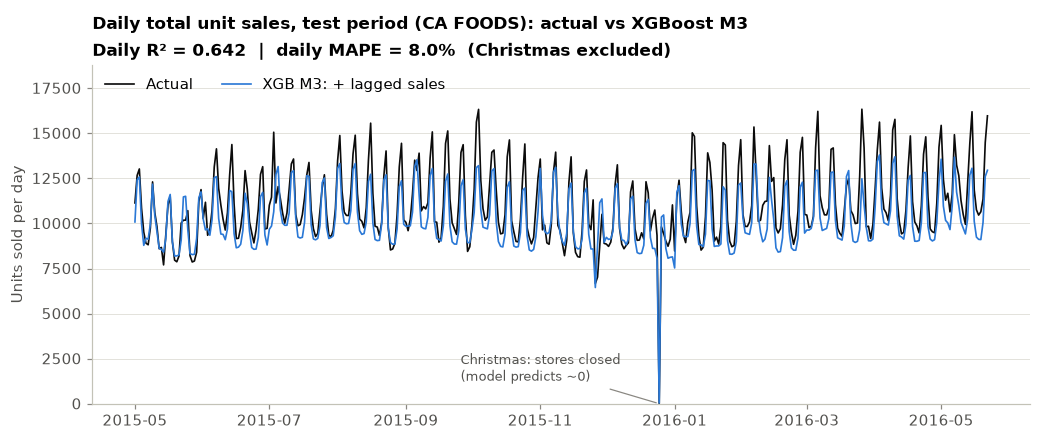

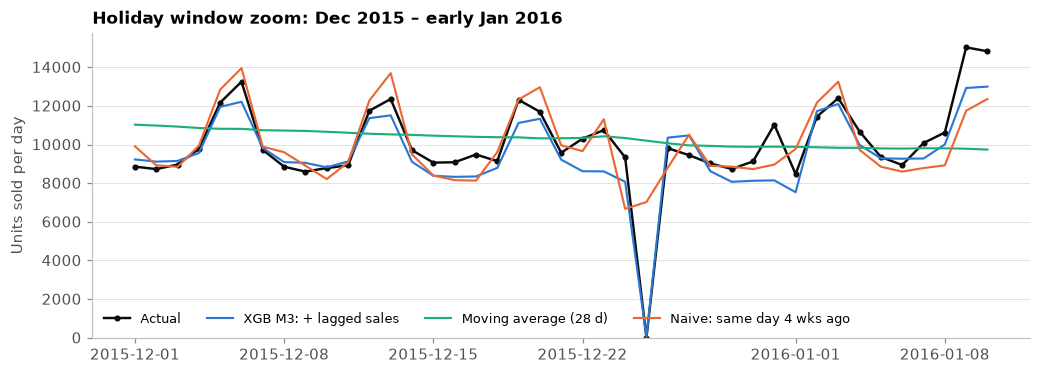

In [11]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(daily.index, daily.y, color=INK, lw=1.1, label="Actual")
ax.plot(daily.index, daily.xgb_M3_full, color=BLUE, lw=1.1, label=NAME["xgb_M3_full"])
ax.annotate("Christmas: stores closed\n(model predicts ~0)", xy=(daily.index[is_xmas][0], daily.y[is_xmas].iloc[0]),
            xytext=(-130, 15), textcoords="offset points", fontsize=8.5, color=INK2,
            arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
m3 = metrics.loc[NAME["xgb_M3_full"]]
ax.set_title(f"Daily total unit sales, test period ({STATE} {CAT}): actual vs XGBoost M3\n"
             f"Daily R² = {m3.Daily_R2:.3f}  |  daily MAPE = {m3.Daily_MAPE:.1%}  (Christmas excluded)", linespacing=1.6)
ax.set_ylabel("Units sold per day")
ax.set_ylim(0, daily[["y", "xgb_M3_full"]].max().max() * 1.15)
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left", ncols=2)
plt.show()

win = daily.loc["2015-12-01":"2016-01-10"]
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(win.index, win.y, color=INK, lw=1.6, marker="o", ms=3, label="Actual")
for m in ["xgb_M3_full", "ma_28", "naive_lag28"]:
    ax.plot(win.index, win[m], color=COLOR[m], lw=1.4, label=NAME[m])
ax.set_title("Holiday window zoom: Dec 2015 – early Jan 2016")
ax.set_ylabel("Units sold per day")
ax.set_ylim(bottom=0)
ax.grid(axis="x", visible=False)
ax.legend(loc="lower left", ncols=4, fontsize=8.5)
plt.show()

### Model comparison (ablation: each feature group added in turn)

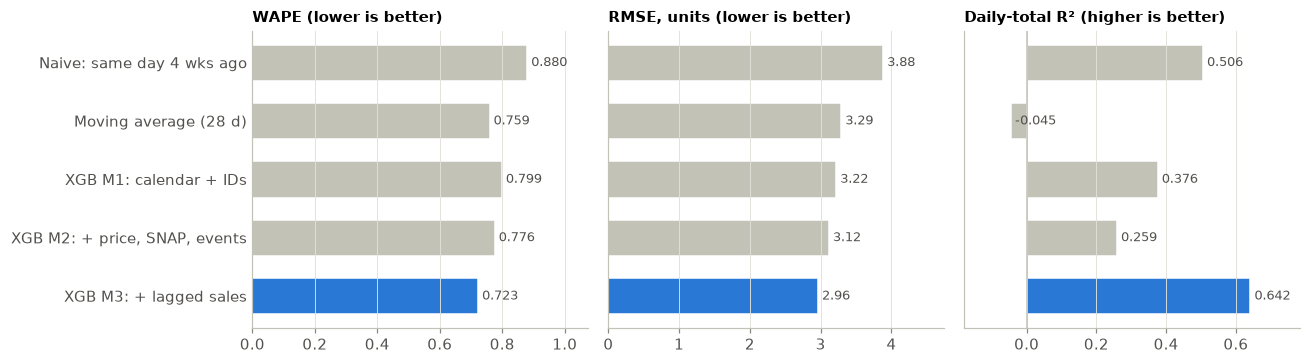

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for ax, (c, title, fmt) in zip(axes, [("WAPE", "WAPE (lower is better)", "{:.3f}"),
                                       ("RMSE", "RMSE, units (lower is better)", "{:.2f}"),
                                       ("Daily_R2", "Daily-total R² (higher is better)", "{:.3f}")]):
    vals = metrics[c].to_numpy()
    ax.barh(metrics.index, vals, color=[BLUE if m == "xgb_M3_full" else NEUTRAL_BAR for m in ORDER],
            height=0.62, edgecolor="white")
    for i, v in enumerate(vals):
        ax.text(v, i, " " + fmt.format(v), va="center", fontsize=8.5, color=INK2)
    ax.set_xlim(min(0, vals.min() * 4), vals.max() * 1.22)
    ax.axvline(0, color=AXIS, lw=1)
    ax.set_title(title, fontsize=10)
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", length=0)
axes[0].invert_yaxis()
plt.tight_layout()
plt.show()

### OLS-style scatter plots: actual vs predicted (dashed = perfect forecast, solid = OLS fit)

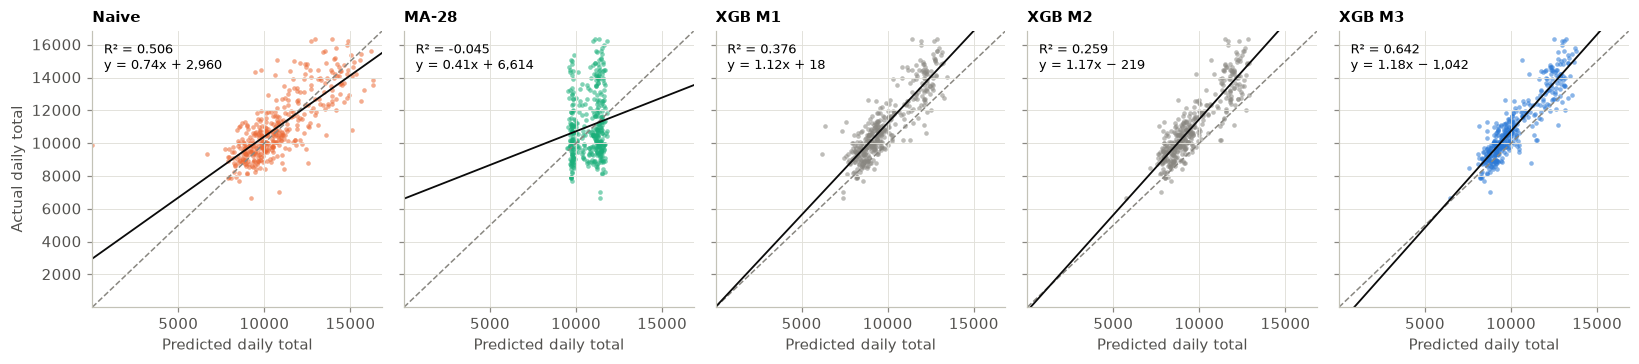

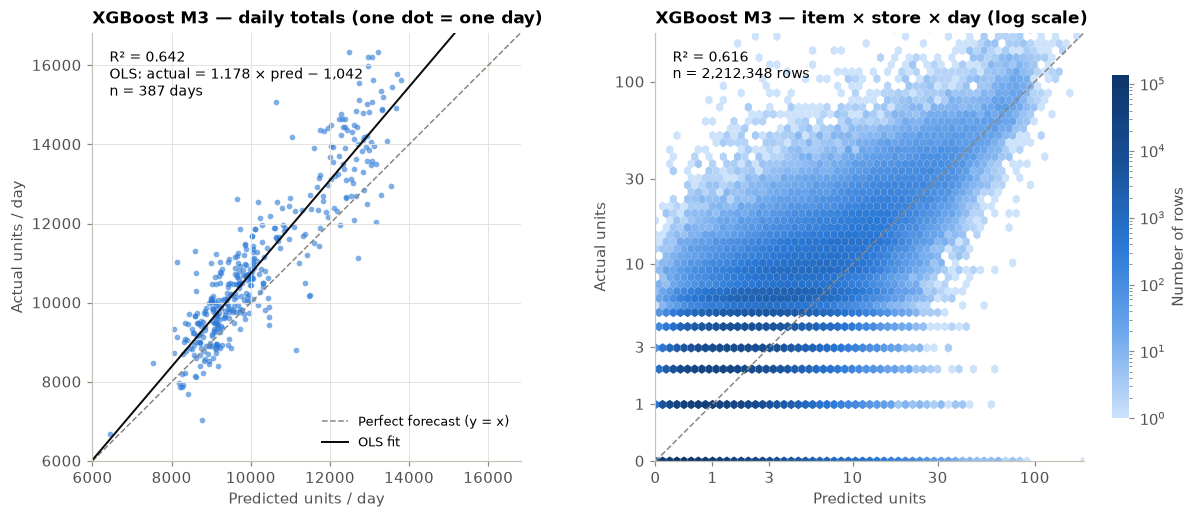

In [13]:
lo = open_days[["y"] + ORDER].min().min() * 0.9
hi = open_days[["y"] + ORDER].max().max() * 1.03
fig, axes = plt.subplots(1, len(ORDER), figsize=(3 * len(ORDER), 3.4), sharex=True, sharey=True)
for ax, m in zip(axes, ORDER):
    xx, yy = open_days[m], open_days.y
    s, b = np.polyfit(xx, yy, 1)
    ax.scatter(xx, yy, s=9, color=COLOR.get(m, MUTED), alpha=0.55, linewidths=0)
    ax.plot([lo, hi], [lo, hi], color=MUTED, lw=1, ls="--")
    ax.plot([lo, hi], [s * lo + b, s * hi + b], color=INK, lw=1.2)
    ax.set_title(SHORT[m], fontsize=10)
    ax.text(0.04, 0.96, f"R² = {r2(yy, xx):.3f}\ny = {s:.2f}x {'+' if b >= 0 else '−'} {abs(b):,.0f}",
            transform=ax.transAxes, va="top", fontsize=8.5)
    ax.set_xlim(lo, hi)
    ax.set_ylim(lo, hi)
    ax.set_xlabel("Predicted daily total")
axes[0].set_ylabel("Actual daily total")
plt.tight_layout()
plt.show()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 4.8))
xx, yy = open_days.xgb_M3_full, open_days.y
lo2, hi2 = min(xx.min(), yy.min()) * 0.93, max(xx.max(), yy.max()) * 1.03
a1.scatter(xx, yy, s=14, color=BLUE, alpha=0.6, linewidths=0)
a1.plot([lo2, hi2], [lo2, hi2], color=MUTED, lw=1, ls="--", label="Perfect forecast (y = x)")
a1.plot([lo2, hi2], [ols.params.iloc[1] * lo2 + ols.params.iloc[0], ols.params.iloc[1] * hi2 + ols.params.iloc[0]],
        color=INK, lw=1.3, label="OLS fit")
a1.set_xlim(lo2, hi2); a1.set_ylim(lo2, hi2); a1.set_aspect("equal")
a1.set_title("XGBoost M3 — daily totals (one dot = one day)")
a1.text(0.04, 0.96, f"R² = {r2(yy, xx):.3f}\nOLS: actual = {ols.params.iloc[1]:.3f} × pred "
        f"{'+' if ols.params.iloc[0] >= 0 else '−'} {abs(ols.params.iloc[0]):,.0f}\nn = {len(xx)} days",
        transform=a1.transAxes, va="top", fontsize=9)
a1.set_xlabel("Predicted units / day"); a1.set_ylabel("Actual units / day")
a1.legend(loc="lower right", fontsize=8.5)

hb = a2.hexbin(np.log1p(te.xgb_M3_full), np.log1p(te.y), gridsize=60, cmap=SEQ, norm=LogNorm(), mincnt=1, linewidths=0)
top = np.log1p(max(te.y.quantile(0.9995), te.xgb_M3_full.max()))
a2.plot([0, top], [0, top], color=MUTED, lw=1, ls="--")
a2.set_xlim(0, top); a2.set_ylim(0, top); a2.set_aspect("equal"); a2.grid(False)
ticks = [t for t in [0, 1, 3, 10, 30, 100] if np.log1p(t) <= top]
a2.set_xticks(np.log1p(ticks), ticks); a2.set_yticks(np.log1p(ticks), ticks)
a2.set_title("XGBoost M3 — item × store × day (log scale)")
a2.text(0.04, 0.96, f"R² = {r2(te.y, te.xgb_M3_full):.3f}\nn = {len(te):,} rows", transform=a2.transAxes, va="top", fontsize=9)
a2.set_xlabel("Predicted units"); a2.set_ylabel("Actual units")
cb = fig.colorbar(hb, ax=a2, shrink=0.8); cb.set_label("Number of rows"); cb.outline.set_visible(False)
plt.tight_layout()
plt.show()

### Residual diagnostics (XGBoost M3, daily totals; positive = under-forecast)

Mean residual: +785 units/day  |  median: +750  |  share of days under-forecast: 83.7%


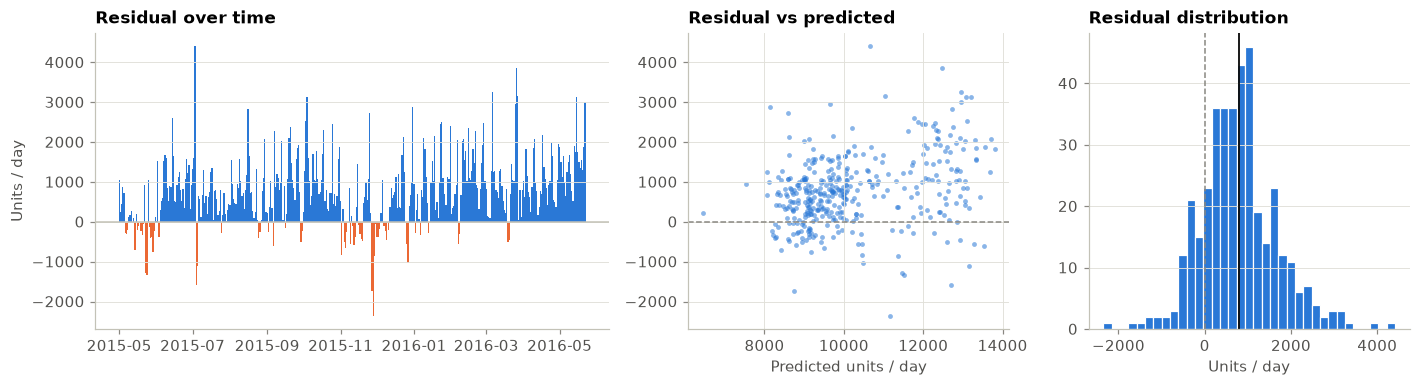

In [14]:
res = open_days.y - open_days.xgb_M3_full
print(f"Mean residual: {res.mean():+,.0f} units/day  |  median: {res.median():+,.0f}  |  "
      f"share of days under-forecast: {(res > 0).mean():.1%}")
fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1.6, 1, 1]})
a1.bar(res.index, res, color=np.where(res >= 0, BLUE, ORANGE), width=1.0)
a1.axhline(0, color=AXIS, lw=1)
a1.set_title("Residual over time"); a1.set_ylabel("Units / day"); a1.grid(axis="x", visible=False)
a2.scatter(open_days.xgb_M3_full, res, s=10, color=BLUE, alpha=0.55, linewidths=0)
a2.axhline(0, color=MUTED, lw=1, ls="--")
a2.set_title("Residual vs predicted"); a2.set_xlabel("Predicted units / day")
a3.hist(res, bins=35, color=BLUE, edgecolor="white", linewidth=0.8)
a3.axvline(0, color=MUTED, lw=1, ls="--"); a3.axvline(res.mean(), color=INK, lw=1.2)
a3.set_title("Residual distribution"); a3.set_xlabel("Units / day"); a3.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

## 8. Feature importance (XGBoost M3)

Gain share by feature group:


,gain_share
Lagged sales / rolling stats,92.8%
Calendar & IDs,4.4%
"Price, SNAP, events",2.8%


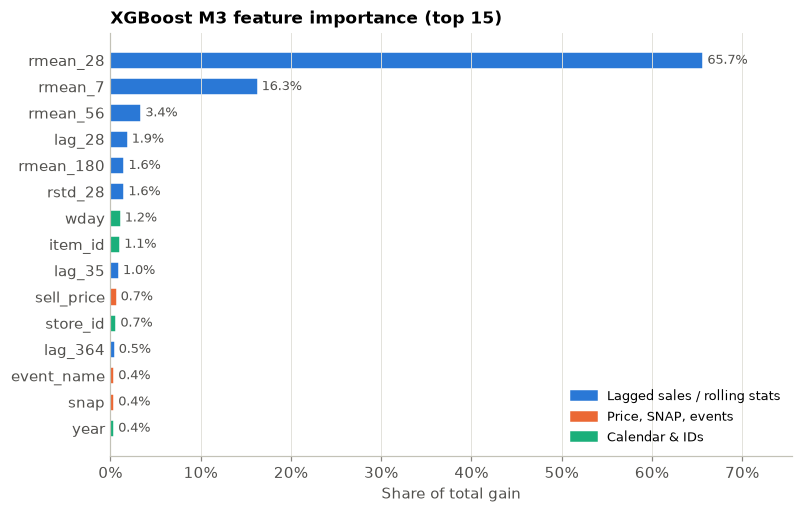

In [15]:
gain = pd.Series(models_fitted["xgb_M3_full"].get_score(importance_type="gain"))
imp = (gain / gain.sum()).sort_values(ascending=False)
def group_of(f):
    if f.startswith(("lag_", "rmean_", "rstd_")):
        return "Lagged sales / rolling stats"
    if f.startswith(("sell_price", "price_", "snap", "is_event", "event_")):
        return "Price, SNAP, events"
    return "Calendar & IDs"
GCOLOR = {"Lagged sales / rolling stats": BLUE, "Price, SNAP, events": ORANGE, "Calendar & IDs": AQUA}
print("Gain share by feature group:")
display(imp.groupby(imp.index.map(group_of)).sum().sort_values(ascending=False).to_frame("gain_share").style.format("{:.1%}"))

top = imp.head(15)[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index, top, color=[GCOLOR[group_of(f)] for f in top.index], height=0.65, edgecolor="white")
for i, v in enumerate(top):
    ax.text(v, i, f" {v:.1%}", va="center", fontsize=8.5, color=INK2)
ax.set_xlim(0, top.max() * 1.15)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.grid(axis="y", visible=False); ax.tick_params(axis="y", length=0)
ax.set_xlabel("Share of total gain")
ax.set_title("XGBoost M3 feature importance (top 15)")
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in GCOLOR.values()], GCOLOR.keys(), loc="lower right", fontsize=8.5)
plt.show()

## 9. Where is forecasting hard? Error (WAPE) by segment

In [16]:
HEROES = ["naive_lag28", "ma_28", "xgb_M3_full"]
def wape_by(key, mapping=None):
    t = te.groupby(key).apply(lambda d: pd.Series({SHORT[m]: (d[m] - d.y).abs().sum() / d.y.sum() for m in HEROES}),
                              include_groups=False)
    return t.rename(index=mapping) if mapping else t

tables = {
    "Sales volume tier": wape_by("volume").reindex([v for v in ["high", "mid", "low", "new_item"] if v in set(te.volume)]),
    "Department": wape_by("dept"),
    "Store": wape_by("store"),
    "Day type": pd.concat([wape_by("snap", {0: "Non-SNAP", 1: "SNAP"}), wape_by("is_event", {0: "No event", 1: "Event"})]),
    "Month": wape_by("month"),
}
for k, t in tables.items():
    print(f"WAPE by {k}:")
    display(t.style.format("{:.3f}").highlight_min(axis=1, color="#cde2fb"))

WAPE by Sales volume tier:


,Naive,MA-28,XGB M3
volume,,,
high,0.755,0.655,0.608
mid,1.131,0.950,0.933
low,1.301,1.150,1.146
new_item,1.079,0.934,0.921


WAPE by Department:


,Naive,MA-28,XGB M3
dept,,,
FOODS_1,1.003,0.837,0.814
FOODS_2,0.998,0.851,0.824
FOODS_3,0.827,0.722,0.680


WAPE by Store:


,Naive,MA-28,XGB M3
store,,,
CA_1,0.868,0.757,0.724
CA_2,0.904,0.785,0.755
CA_3,0.811,0.695,0.641
CA_4,1.033,0.881,0.868


WAPE by Day type:


,Naive,MA-28,XGB M3
Non-SNAP,0.887,0.768,0.725
SNAP,0.867,0.743,0.717
No event,0.878,0.757,0.723
Event,0.902,0.787,0.717


WAPE by Month:


,Naive,MA-28,XGB M3
month,,,
2015-05,0.915,0.797,0.751
2015-06,0.918,0.800,0.751
2015-07,0.898,0.754,0.719
2015-08,0.837,0.731,0.716
2015-09,0.843,0.732,0.713
2015-10,0.895,0.777,0.726
2015-11,0.952,0.848,0.772
2015-12,0.936,0.842,0.771
2016-01,0.895,0.746,0.709


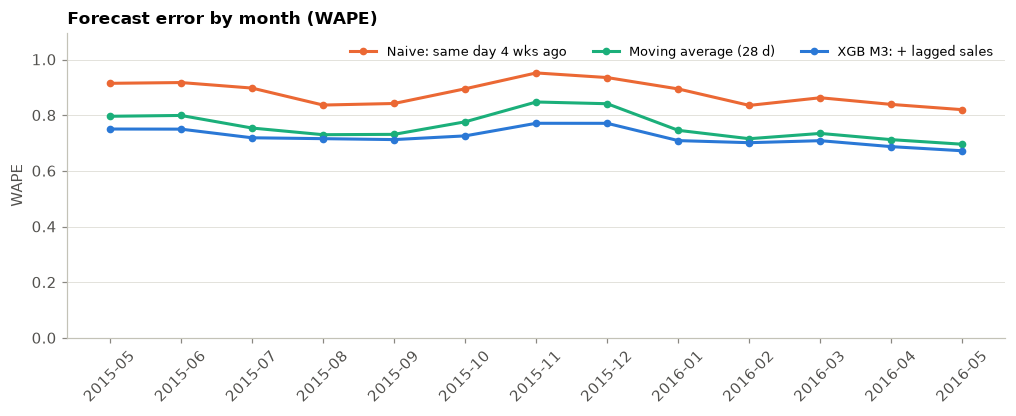

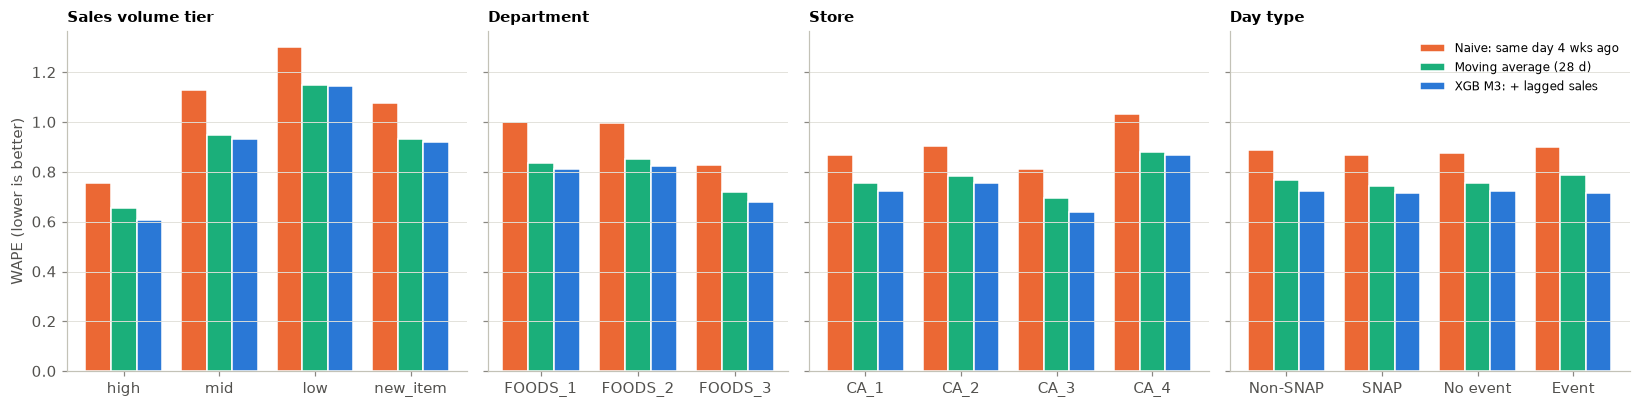

In [17]:
by_month = tables["Month"]
fig, ax = plt.subplots(figsize=(11, 3.6))
for m in HEROES:
    ax.plot(by_month.index, by_month[SHORT[m]], color=COLOR[m], lw=2, marker="o", ms=4, label=NAME[m])
ax.set_title("Forecast error by month (WAPE)")
ax.set_ylabel("WAPE"); ax.set_ylim(0, by_month.values.max() * 1.15)
ax.grid(axis="x", visible=False); ax.tick_params(axis="x", rotation=45)
ax.legend(loc="upper right", ncols=3, fontsize=8.5)
plt.show()

panels = [(k, tables[k]) for k in ["Sales volume tier", "Department", "Store", "Day type"]]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharey=True, gridspec_kw={"width_ratios": [max(len(t), 3) for _, t in panels]})
w = 0.8 / len(HEROES)
for ax, (title, t) in zip(axes, panels):
    xs = np.arange(len(t))
    for k, m in enumerate(HEROES):
        ax.bar(xs + (k - (len(HEROES) - 1) / 2) * w, t[SHORT[m]], width=w, color=COLOR[m], edgecolor="white", label=NAME[m])
    ax.set_xticks(xs, t.index)
    ax.set_title(title, fontsize=10); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("WAPE (lower is better)")
axes[-1].legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

## 10. Descriptive patterns in the training period (SNAP, events, weekday)

SNAP-day sales lift by department:


,lift
dept,
FOODS_1,+2.2%
FOODS_2,+22.7%
FOODS_3,+11.5%


Event-day vs non-event-day sales: -4.1%
Weekend vs weekday sales: +32.3%


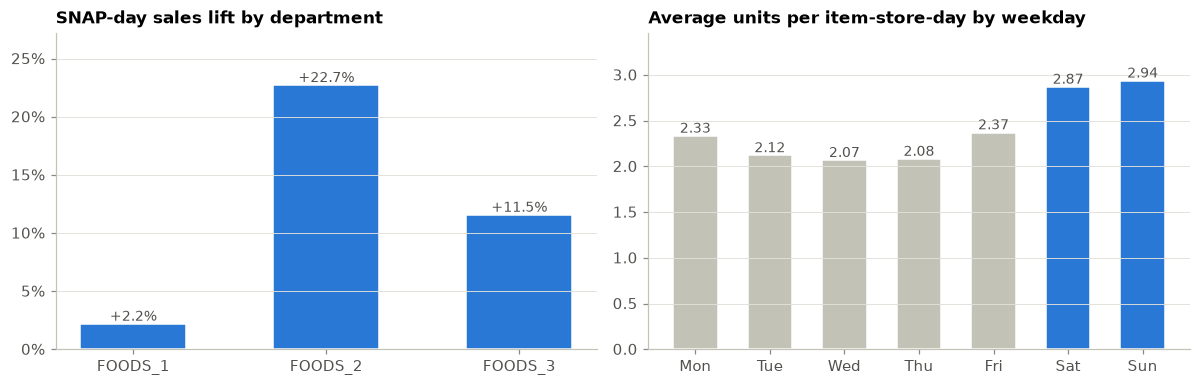

In [18]:
trn = pd.DataFrame({"y": y[:i_te], "snap": X[:i_te, col["snap"]], "is_event": X[:i_te, col["is_event"]],
                    "wday": X[:i_te, col["wday"]], "dept": meta.dept_id.to_numpy()[sid[:i_te]]})
snap_lift = trn.groupby(["dept", "snap"]).y.mean().unstack().pipe(lambda t: t[1] / t[0] - 1)
event_lift = trn[trn.is_event == 1].y.mean() / trn[trn.is_event == 0].y.mean() - 1
WD = [(3, "Mon"), (4, "Tue"), (5, "Wed"), (6, "Thu"), (7, "Fri"), (1, "Sat"), (2, "Sun")]
wday_mean = trn.groupby("wday").y.mean()
wday_mean = pd.Series([wday_mean[k] for k, _ in WD], index=[l for _, l in WD])

print("SNAP-day sales lift by department:")
display(snap_lift.to_frame("lift").style.format("{:+.1%}"))
print(f"Event-day vs non-event-day sales: {event_lift:+.1%}")
print(f"Weekend vs weekday sales: {wday_mean[['Sat', 'Sun']].mean() / wday_mean.iloc[:5].mean() - 1:+.1%}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
a1.bar(snap_lift.index, snap_lift, color=BLUE, width=0.55, edgecolor="white")
for i, v in enumerate(snap_lift):
    a1.text(i, v, f"{v:+.1%}", ha="center", va="bottom", fontsize=9, color=INK2)
a1.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
a1.set_ylim(0, snap_lift.max() * 1.2); a1.grid(axis="x", visible=False)
a1.set_title("SNAP-day sales lift by department")
a2.bar(wday_mean.index, wday_mean, color=[BLUE if d in ("Sat", "Sun") else NEUTRAL_BAR for d in wday_mean.index],
       width=0.6, edgecolor="white")
for i, v in enumerate(wday_mean):
    a2.text(i, v, f"{v:.2f}", ha="center", va="bottom", fontsize=9, color=INK2)
a2.set_ylim(0, wday_mean.max() * 1.18); a2.grid(axis="x", visible=False)
a2.set_title("Average units per item-store-day by weekday")
plt.tight_layout()
plt.show()

## 11. Save predictions (for comparison with OLS / NN / TimesFM)

In [19]:
out = Path(DATA_DIR) / "outputs" / f"xgb_{STATE}_{CAT}_notebook"
out.mkdir(parents=True, exist_ok=True)
metrics.to_csv(out / "metrics_overall.csv")
daily.to_csv(out / "daily_totals.csv")
te.drop(columns=["date"]).to_csv(out / "test_predictions.csv.gz", index=False)
print("Saved to", out.resolve())
print(f"Total runtime: {time.time() - t0:.0f}s")

Saved to outputs/xgb_CA_FOODS_notebook
Total runtime: 737s


## Key findings (CA FOODS)
1. **Lagged sales carry most of the signal.** Adding lag / rolling features (M2 → M3) gives the largest error drop, and recent sales level (`rmean_28`, `rmean_7`) dominates feature importance.
2. **Calendar + price alone do not beat a simple moving average** at the item level: without sales history the model cannot tell each item's typical volume.
3. **XGBoost M3 is best on every metric** (lowest RMSE / MAE / WAPE, highest R²), and is the only model whose daily totals track the weekly cycle well.
4. **The model learned Christmas closures** (predicts ~0), which the baselines miss.
5. **Systematic under-forecast (~7%)**, mostly on high-volume weekend days (OLS slope > 1) — a known Tweedie-loss effect and the main improvement opportunity.
6. **SNAP matters by department** (largest for FOODS_2, smallest for FOODS_1); errors are highest for low-volume items and in November–December.